# Segmentação e previsão de cancelamento de clientes de uma operadora de telecomunicações

**Projeto de Machine Learning Clássico (ABP)**
**Tema: separação e previsão de cancelamento de clientes de uma empresa de telecomunicações**

Grupo 6: Otávio Bonini e Cauã Medeiros
Professor: Rodrigo Ramos Silva

**Base:** Telco Customer Churn (IBM), 7.043 clientes de uma operadora fictícia da Califórnia.

**Pergunta:** quais clientes estão perto de cancelar, que tipo de cliente eles são e quanto de receita está em risco?

**O que o projeto faz:**
1. **Separa** os clientes em grupos parecidos com **K-means** (não usa a resposta, só o perfil).
2. **Prevê** quem vai cancelar com **Árvore de Decisão, SVM, Random Forest e Gradient Boosting**.
3. **Junta as duas coisas**: calcula a receita em risco de cada cliente e monta uma lista de quem a equipe de retenção deve procurar primeiro, com uma ação pra cada grupo.

> Pra rodar: no Colab, clique em *Ambiente de execução > Executar tudo*. Leva uns 3 minutos (a parte mais lenta é o GridSearch).

## 1. O problema

**Churn** é o nome que o mercado dá pro cancelamento: o cliente que sai da empresa. Numa operadora de telecom isso pesa muito, porque a receita é **recorrente**: cada cliente paga todo mês. Quando ele cancela, a empresa perde aquela mensalidade em todos os meses seguintes.

**O tamanho do mercado.** O Brasil terminou setembro de 2026 com **281,74 milhões de conexões móveis ativas** (Teletime, com dados do Radar da Telecom). Só na TIM, o **churn mensal foi de 3%** no 2º trimestre de 2026 (Mobile Time). Ou seja: de cada 100 clientes, 3 saem por mês, e a empresa precisa repor esses clientes só pra ficar no mesmo lugar.

**Por que segurar é melhor que repor.** Conquistar um cliente novo custa de **5 a 25 vezes mais** do que manter um que já existe, segundo a Harvard Business Review (Gallo, 2014). O mesmo artigo cita a Bain & Company: aumentar a retenção em 5% pode aumentar o lucro de 25% a 95%. São estimativas muito citadas e variam por setor, mas a ideia é clara: perder cliente sai caro.

**Como é hoje, sem modelo.** A empresa normalmente só descobre que o cliente vai sair quando ele já ligou pedindo o cancelamento. Aí resta oferecer desconto na hora, quando a decisão já está tomada. A outra opção, dar desconto pra todo mundo, joga dinheiro fora com quem nunca ia sair.

**O que a pesquisa diz.** Verbeke et al. (2012), no *European Journal of Operational Research*, testaram vários classificadores em **11 bases reais de operadoras de telecom** do mundo todo. Três conclusões importam pra gente:
- poucas variáveis já bastam pra prever churn bem;
- um grupo grande de modelos chega em resultados parecidos;
- o modelo deve ser escolhido pensando no **lucro da campanha de retenção**, e não só na acurácia.

**Nossa proposta.** Em vez de só "prever churn", o projeto responde três perguntas que ajudam a decidir:
1. **Que tipos de cliente existem?** (K-means)
2. **Quem tem chance alta de sair?** (classificação)
3. **Quanto dinheiro está em jogo e por onde começar?** (receita em risco = chance de cancelar × mensalidade)

## 2. Dataset

| Item | Descrição |
|---|---|
| Nome | Telco Customer Churn |
| Fonte | IBM (amostra de dados), também publicada no Kaggle |
| Link | https://www.kaggle.com/datasets/blastchar/telco-customer-churn |
| Arquivo usado | https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv |
| Data de acesso | 06/11/2026 |
| Tamanho | 7.043 linhas (clientes) e 21 colunas |
| O que representa | Segundo a IBM, uma operadora **fictícia** que oferecia telefone fixo e internet para 7.043 clientes na Califórnia, no 3º trimestre |

**Por que essa base:** é a base pública mais usada pra estudar churn em telecom. Tem o que a operadora de verdade teria: tipo de contrato, tempo de casa, serviços contratados, forma de pagamento, valor da conta e se o cliente cancelou.

**Dicionário das colunas**

| Coluna | O que é |
|---|---|
| customerID | código do cliente |
| gender | sexo |
| SeniorCitizen | se é idoso (1 = sim) |
| Partner | se tem cônjuge |
| Dependents | se tem dependentes |
| tenure | **meses como cliente** (tempo de casa) |
| PhoneService | se tem telefone |
| MultipleLines | se tem mais de uma linha |
| InternetService | tipo de internet: DSL, fibra (Fiber optic) ou nenhuma |
| OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport | serviços extras: segurança, backup, proteção do aparelho e suporte técnico |
| StreamingTV, StreamingMovies | streaming de TV e de filmes |
| Contract | **tipo de contrato**: mensal (Month-to-month), 1 ano ou 2 anos |
| PaperlessBilling | se recebe a fatura só digital |
| PaymentMethod | forma de pagamento |
| MonthlyCharges | **valor da mensalidade** (em dólares) |
| TotalCharges | total que o cliente já pagou |
| Churn | **se o cliente cancelou** (é o que queremos prever) |

## 3. Bibliotecas e carregamento dos dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

# Padrão dos gráficos
plt.rcParams.update({'figure.dpi': 100, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 11})
AZUL, VERMELHO = '#1A62C6', '#C5221F'   # ficou / cancelou

In [2]:
# Arquivo da IBM no GitHub (não precisa de login no Kaggle)
URL = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
df = pd.read_csv(URL)

print(df.shape[0], 'linhas (clientes)')
print(df.shape[1], 'colunas')
df.head()

7043 linhas (clientes)
21 colunas


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 4. Primeira olhada na base

Antes de mexer em qualquer coisa, a gente confere os tipos de cada coluna, se tem valor faltando e se tem cliente repetido.

In [3]:
# Tipos das colunas
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [4]:
print('valores vazios por coluna:', df.isna().sum().sum())
print('clientes repetidos:', df['customerID'].duplicated().sum())

# TotalCharges veio como texto
convertido = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('linhas de TotalCharges que não viram número:', convertido.isna().sum())
df.loc[convertido.isna(), ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

valores vazios por coluna: 0
clientes repetidos: 0
linhas de TotalCharges que não viram número: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


**O que achamos:** a base não tem nulo "visível" e nem cliente repetido. Mas a coluna **TotalCharges veio como texto**, porque tem **11 linhas com um espaço em branco** no lugar do número. Todas são clientes com **tenure = 0**, ou seja, que acabaram de entrar e ainda não pagaram nenhuma conta. Por isso o certo é colocar **0** nelas, e não apagar as linhas.

## 5. Limpeza

In [5]:
# TotalCharges: texto -> número (vazios = 0, clientes novos)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)

# SeniorCitizen: 0/1 -> No/Yes, igual às outras categorias
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})

# Churn (alvo): Yes = 1, No = 0
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

print(df[['TotalCharges', 'SeniorCitizen', 'Churn']].dtypes)
print('nulos depois da limpeza:', df.isna().sum().sum())

TotalCharges     float64
SeniorCitizen        str
Churn              int64
dtype: object
nulos depois da limpeza: 0


## 6. Feature engineering (coluna nova)

Criamos uma coluna que não existia: **qtd_servicos**, quantos serviços o cliente contrata (telefone, segunda linha, internet, segurança, backup, proteção, suporte, TV e filmes). A ideia é testar se quem tem mais coisa contratada fica mais "preso" à operadora.

O **customerID** não entra no modelo (é só um código, não diz nada sobre o cliente), mas guardamos ele pra montar a lista final de clientes.

In [6]:
servicos = ['PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
            'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

# Quantos serviços o cliente tem (+1 se tem internet)
df['qtd_servicos'] = (df[servicos] == 'Yes').sum(axis=1) + (df['InternetService'] != 'No').astype(int)

df['qtd_servicos'].value_counts().sort_index()

qtd_servicos
1    1264
2     859
3     846
4     965
5     922
6     908
7     676
8     395
9     208
Name: count, dtype: int64

## 7. Análise exploratória (EDA)

### 7.1 Quantos clientes cancelaram?

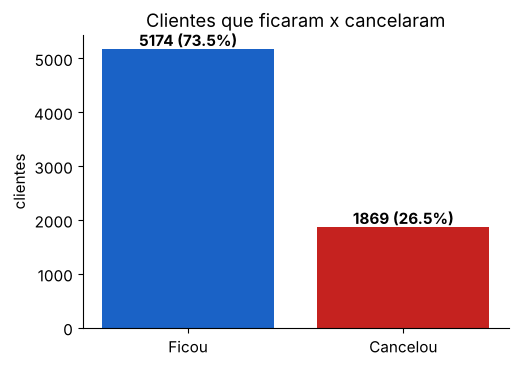

Taxa de cancelamento da base: 26.5%


In [7]:
contagem = df['Churn'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.bar(['Ficou', 'Cancelou'], contagem.values, color=[AZUL, VERMELHO])
for i, v in enumerate(contagem.values):
    ax.text(i, v + 60, f'{v} ({v / len(df):.1%})', ha='center', fontweight='bold')
ax.set_title('Clientes que ficaram x cancelaram')
ax.set_ylabel('clientes')
plt.show()

print(f"Taxa de cancelamento da base: {df['Churn'].mean():.1%}")

**Leitura:** cerca de **1 em cada 4 clientes cancelou (26,5%)**. As classes são **desbalanceadas**: tem quase 3 clientes que ficam pra cada 1 que sai. Isso importa porque um modelo "preguiçoso" que chuta "fica" pra todo mundo já acertaria 73,5%. Por isso **acurácia sozinha engana** aqui e a gente vai olhar Recall, Precision, F1 e ROC-AUC.

### 7.2 Quem cancela mais?

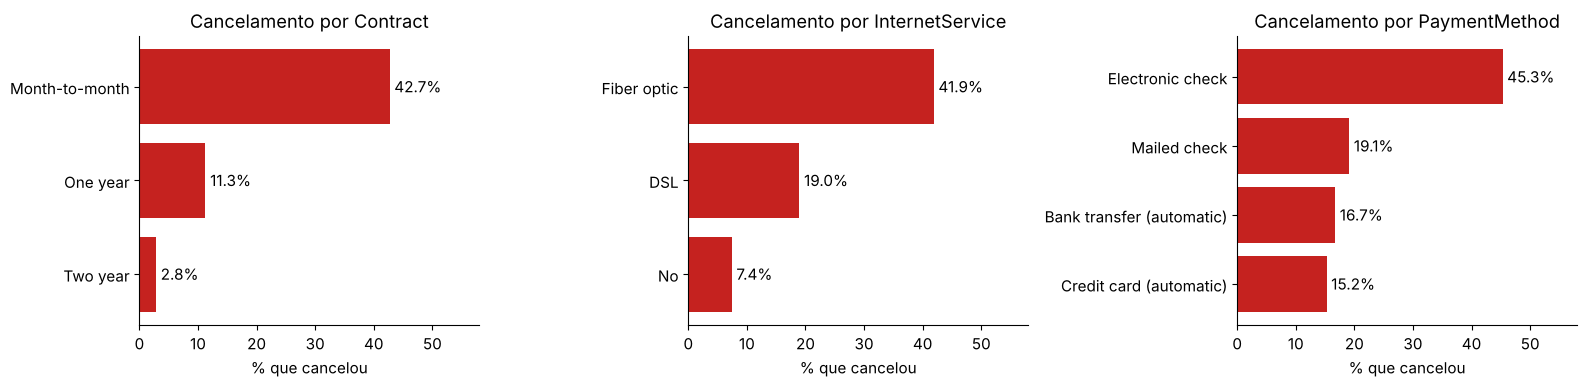

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, coluna in zip(axes, ['Contract', 'InternetService', 'PaymentMethod']):
    # % que cancelou em cada categoria
    taxa = (df.groupby(coluna)['Churn'].mean() * 100).sort_values()
    ax.barh(taxa.index, taxa.values, color=VERMELHO)
    for i, v in enumerate(taxa.values):
        ax.text(v + 0.8, i, f'{v:.1f}%', va='center')
    ax.set_title(f'Cancelamento por {coluna}')
    ax.set_xlim(0, 58)
    ax.set_xlabel('% que cancelou')

plt.tight_layout()
plt.show()

**Leitura:**
- **Contrato mensal** cancela muito mais (42,7%) do que contrato de 1 ano (11,3%) e de 2 anos (2,8%). Faz sentido: no mensal o cliente pode sair a qualquer momento sem multa.
- **Fibra óptica** cancela mais (41,9%) do que DSL (19,0%). Fibra é o plano mais caro, então pode ser preço ou qualidade do serviço.
- **Electronic check** (boleto/cheque eletrônico) cancela 45,3%, contra uns 15% a 17% de quem paga no **débito automático** ou **cartão**. Quem paga automático "esquece" da conta; quem paga na mão pensa todo mês se vale a pena.

### 7.3 Tempo de casa e valor da conta

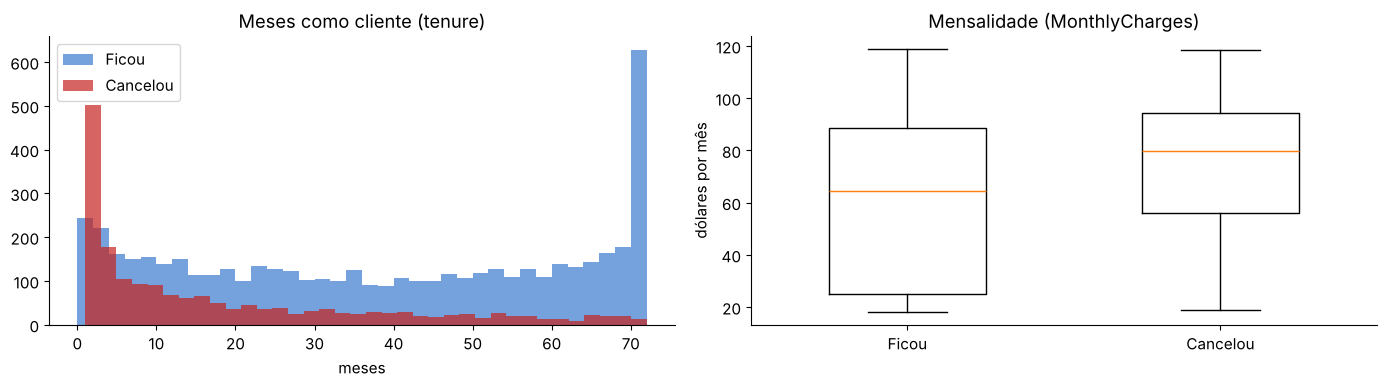

          tenure  MonthlyCharges
Churn                           
Ficou       38.0          64.425
Cancelou    10.0          79.650


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Tempo de casa
axes[0].hist(df.loc[df['Churn'] == 0, 'tenure'], bins=36, alpha=0.6, color=AZUL, label='Ficou')
axes[0].hist(df.loc[df['Churn'] == 1, 'tenure'], bins=36, alpha=0.7, color=VERMELHO, label='Cancelou')
axes[0].set_title('Meses como cliente (tenure)')
axes[0].set_xlabel('meses')
axes[0].legend()

# Mensalidade
axes[1].boxplot([df.loc[df['Churn'] == 0, 'MonthlyCharges'], df.loc[df['Churn'] == 1, 'MonthlyCharges']],
                widths=0.5)
axes[1].set_xticks([1, 2], ['Ficou', 'Cancelou'])
axes[1].set_title('Mensalidade (MonthlyCharges)')
axes[1].set_ylabel('dólares por mês')

plt.tight_layout()
plt.show()

print(df.groupby('Churn')[['tenure', 'MonthlyCharges']].median().rename(index={0: 'Ficou', 1: 'Cancelou'}))

**Leitura:**
- Quem cancela é, na maioria, **cliente novo**: a mediana de quem saiu é de **10 meses** de casa, contra **38 meses** de quem ficou. Os primeiros meses são o momento mais perigoso.
- Quem cancela paga **mais caro**: mediana de **79,65** por mês contra **64,4** de quem ficou (em dólares).

### 7.4 Correlação entre as variáveis numéricas

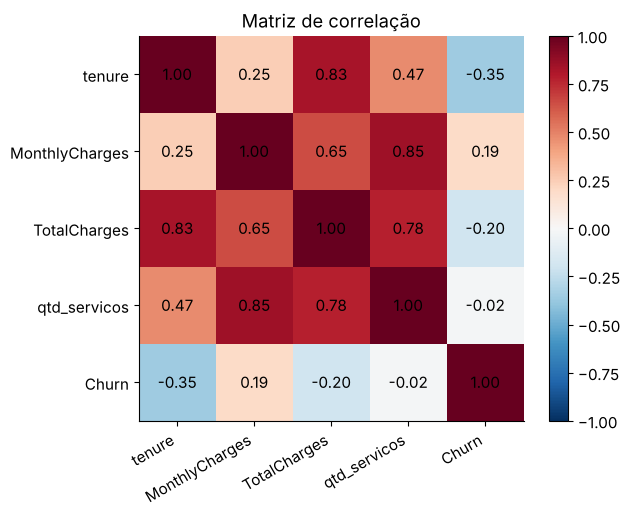

In [10]:
numericas = ['tenure', 'MonthlyCharges', 'TotalCharges', 'qtd_servicos', 'Churn']
corr = df[numericas].corr()   # de -1 a +1

fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(numericas)), numericas, rotation=30, ha='right')
ax.set_yticks(range(len(numericas)), numericas)
for i in range(len(numericas)):
    for j in range(len(numericas)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center')
fig.colorbar(im)
ax.set_title('Matriz de correlação')
plt.show()

**Leitura:**
- **tenure** tem correlação **negativa** com Churn (-0,35): quanto mais tempo de casa, menos cancela.
- **MonthlyCharges** tem correlação **positiva** (+0,19): conta mais cara, mais cancelamento.
- **TotalCharges** é quase o tempo de casa vezes a mensalidade, por isso tem correlação alta com as duas (0,83 com tenure). É uma informação repetida, mas a gente deixa porque não atrapalha os modelos de árvore.
- **qtd_servicos** quase não tem correlação com Churn (-0,02). Ou seja, a nossa ideia de que "quem tem mais serviço fica mais preso" **não se confirmou** sozinha. Ela anda muito junto com a mensalidade (0,85): mais serviço = conta mais cara.

**Hipóteses que a EDA levantou:** cliente **novo**, de **contrato mensal**, com **fibra**, conta **alta** e pagando por **electronic check** é o perfil de maior risco.

## 8. Parte 1: separação dos clientes com K-means

**O que é:** o K-means junta os clientes em **K grupos** de pessoas parecidas. Ele não sabe quem cancelou; ele só olha o perfil. Funciona assim:
1. sorteia K pontos como "centro" dos grupos;
2. cada cliente vai pro centro mais próximo;
3. o centro anda pro meio dos clientes do grupo;
4. repete até parar de mudar.

**Objetivo do agrupamento** (no lugar do "target", já que o K-means não tem alvo): separar a base em perfis que a área comercial entenda e consiga tratar de jeito diferente.

**Variáveis usadas:** **tenure** (há quanto tempo é cliente) e **MonthlyCharges** (quanto paga). São as duas perguntas que a empresa mais faz sobre um cliente: *"é novo ou antigo?"* e *"paga muito ou pouco?"*. Testamos também colocar quantidade de serviços e tipo de contrato, mas a nota dos grupos (silhouette) ficou pior e os grupos ficaram mais difíceis de explicar.

**Importante:** a coluna **Churn não entra** no K-means. A gente só usa ela **depois**, pra ver quanto cada grupo cancela.

In [11]:
colunas_grupo = ['tenure', 'MonthlyCharges']

# Padroniza as duas colunas (mesma escala)
scaler_grupo = StandardScaler()
X_grupo = scaler_grupo.fit_transform(df[colunas_grupo])

# Testa de 2 a 8 grupos
ks = range(2, 9)
inercias, silhuetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    rotulos = km.fit_predict(X_grupo)
    inercias.append(km.inertia_)                          # menor = melhor
    silhuetas.append(silhouette_score(X_grupo, rotulos))  # maior = melhor

pd.DataFrame({'K': list(ks), 'inércia': np.round(inercias), 'silhouette': np.round(silhuetas, 3)})

,K,inércia,silhouette
0,2,7841.0,0.411
1,3,4623.0,0.446
2,4,2845.0,0.476
3,5,2338.0,0.430
4,6,1929.0,0.415
5,7,1556.0,0.434
6,8,1345.0,0.433


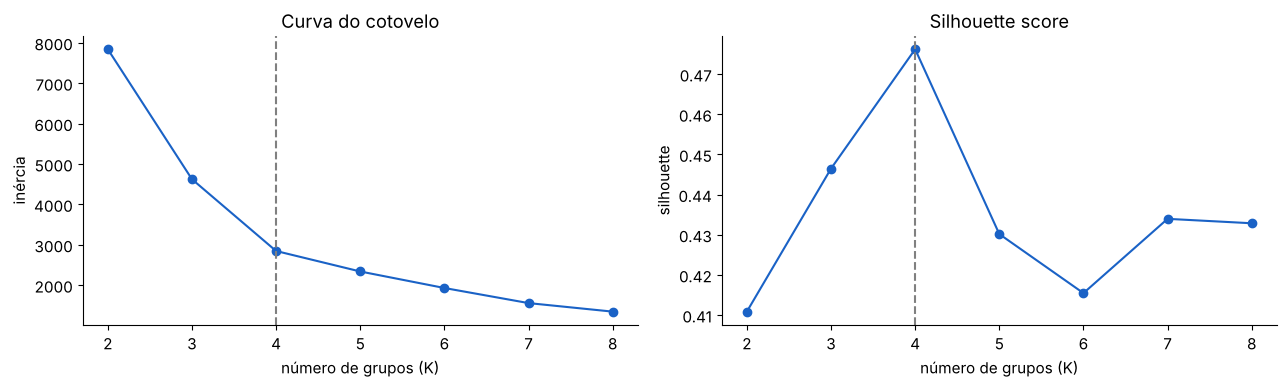

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(list(ks), inercias, marker='o', color=AZUL)
axes[0].set_title('Curva do cotovelo')
axes[0].set_xlabel('número de grupos (K)')
axes[0].set_ylabel('inércia')
axes[0].axvline(4, color='gray', ls='--')

axes[1].plot(list(ks), silhuetas, marker='o', color=AZUL)
axes[1].set_title('Silhouette score')
axes[1].set_xlabel('número de grupos (K)')
axes[1].set_ylabel('silhouette')
axes[1].axvline(4, color='gray', ls='--')

plt.tight_layout()
plt.show()

**Escolha do K = 4:**
- na **curva do cotovelo**, a inércia cai muito até K = 4 e depois passa a cair devagar (é o "cotovelo");
- o **silhouette** é o **maior em K = 4** (0,476);
- e 4 grupos é um número que dá pra explicar e transformar em ação.

In [13]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
rotulo = kmeans.fit_predict(X_grupo)

# Centros de volta pra meses e dólares
centros = pd.DataFrame(scaler_grupo.inverse_transform(kmeans.cluster_centers_), columns=colunas_grupo)

# Nome do grupo pelo centro: novo/antigo e conta alta/baixa
def nomear(tenure, mensalidade):
    tempo = 'Antigos' if tenure >= 30 else 'Novos'
    conta = 'conta alta' if mensalidade >= 60 else 'conta baixa'
    return f'{tempo} com {conta}'

nomes = {i: nomear(c['tenure'], c['MonthlyCharges']) for i, c in centros.iterrows()}
df['grupo'] = pd.Series(rotulo, index=df.index).map(nomes)

centros.index = [nomes[i] for i in centros.index]
centros.round(1)

,tenure,MonthlyCharges
Novos com conta baixa,10.5,32.5
Antigos com conta alta,58.8,93.0
Novos com conta alta,14.8,81.2
Antigos com conta baixa,54.1,34.0


In [14]:
# Perfil de cada grupo (Churn só pra interpretar)
perfil = df.groupby('grupo').agg(
    clientes=('Churn', 'size'),
    meses_de_casa=('tenure', 'mean'),
    mensalidade=('MonthlyCharges', 'mean'),
    servicos=('qtd_servicos', 'mean'),
    pct_contrato_mensal=('Contract', lambda s: (s == 'Month-to-month').mean() * 100),
    pct_fibra=('InternetService', lambda s: (s == 'Fiber optic').mean() * 100),
    pct_sem_internet=('InternetService', lambda s: (s == 'No').mean() * 100),
    pct_cancelou=('Churn', lambda s: s.mean() * 100),
).sort_values('pct_cancelou', ascending=False).round(1)

ordem_grupos = perfil.index.tolist()   # do que mais cancela pro que menos
CORES = dict(zip(ordem_grupos, ['#C5221F', '#E37400', '#1A62C6', '#188038']))
perfil

,clientes,meses_de_casa,mensalidade,servicos,pct_contrato_mensal,pct_fibra,pct_sem_internet,pct_cancelou
grupo,,,,,,,,
Novos com conta alta,2204,14.8,81.2,4.4,86.9,78.4,0.0,49.2
Novos com conta baixa,1732,10.5,32.5,2.0,72.7,0.0,49.8,24.5
Antigos com conta alta,1952,58.7,93.0,6.7,26.8,70.1,0.0,15.6
Antigos com conta baixa,1155,54.1,34.0,2.6,15.2,0.0,57.5,4.8


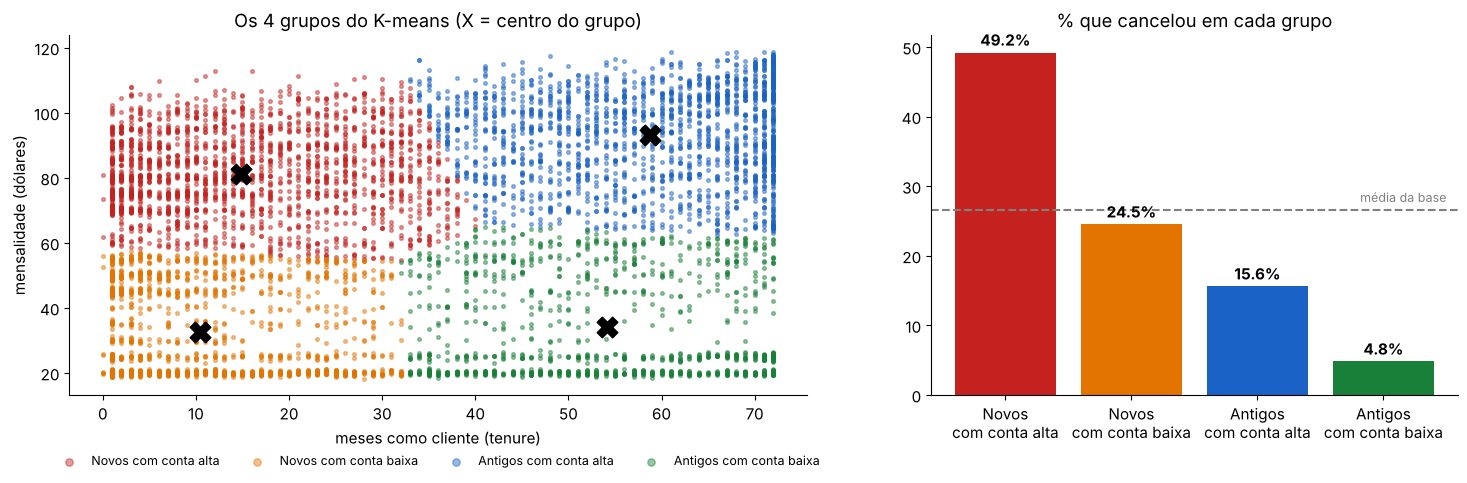

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1.4, 1]})

# Cada ponto é um cliente; X = centro
for g in ordem_grupos:
    parte = df[df['grupo'] == g]
    axes[0].scatter(parte['tenure'], parte['MonthlyCharges'], s=7, alpha=0.45, color=CORES[g], label=g)
axes[0].scatter(centros['tenure'], centros['MonthlyCharges'], marker='X', s=220, color='black')
axes[0].set_xlabel('meses como cliente (tenure)')
axes[0].set_ylabel('mensalidade (dólares)')
axes[0].set_title('Os 4 grupos do K-means (X = centro do grupo)')
axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=4, fontsize=9, markerscale=2, frameon=False)

# % que cancelou por grupo
axes[1].bar(range(K), perfil['pct_cancelou'], color=[CORES[g] for g in ordem_grupos])
axes[1].set_xticks(range(K), [g.replace(' com ', '\ncom ') for g in ordem_grupos])
for i, v in enumerate(perfil['pct_cancelou']):
    axes[1].text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
axes[1].axhline(df['Churn'].mean() * 100, color='gray', ls='--')
axes[1].text(K - 0.5, df['Churn'].mean() * 100 + 1.2, 'média da base', ha='right', color='gray', fontsize=9)
axes[1].set_title('% que cancelou em cada grupo')

plt.tight_layout()
plt.show()

**Os 4 perfis que o K-means encontrou:**

| Grupo | Como é | Cancelamento |
|---|---|---|
| **Novos com conta alta** | ~15 meses de casa, pagam ~81 por mês, quase todos com fibra (78%) e contrato mensal (87%) | **49,2%**, o pior. Quase metade sai |
| **Novos com conta baixa** | ~10 meses, pagam ~32, metade nem tem internet | **24,5%** |
| **Antigos com conta alta** | ~59 meses, pagam ~93, pacote completo (6,7 serviços em média) | **15,6%** |
| **Antigos com conta baixa** | ~54 meses, pagam ~34, plano básico | **4,8%**, os mais fiéis |

A separação confirma o que a EDA mostrou: o **tempo de casa** é o que mais separa quem fica de quem sai, e a **conta alta** piora o risco de quem ainda é novo. O grupo "Novos com conta alta" tem **31% dos clientes** mas quase o dobro da taxa média de cancelamento.

## 9. Parte 2: previsão de cancelamento (classificação)

Agora o objetivo muda: prever, **cliente por cliente**, se ele vai cancelar (1) ou não (0).

### 9.1 Separar X (informações) e y (resposta) e dividir treino e teste

In [16]:
# X = informações do cliente, y = se cancelou
X = df.drop(columns=['customerID', 'Churn', 'grupo'])
y = df['Churn']

# 80% treino, 20% teste, mesma proporção de cancelados
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print('treino:', X_treino.shape[0], 'clientes |', f'{y_treino.mean():.1%} cancelaram')
print('teste: ', X_teste.shape[0], 'clientes |', f'{y_teste.mean():.1%} cancelaram')

treino: 5634 clientes | 26.5% cancelaram
teste:  1409 clientes | 26.5% cancelaram


### 9.2 Pré-processamento

- **Colunas de número** (tenure, mensalidade, total pago, qtd de serviços): **StandardScaler**. O **SVM precisa disso**, porque ele trabalha com distância, igual o K-means. As árvores não precisam, mas também não atrapalha.
- **Colunas de texto** (contrato, internet, pagamento etc.): **OneHotEncoder**, que transforma cada opção numa coluna de 0 e 1. O `drop='first'` tira uma das opções de cada coluna, porque ela já fica implícita (se não é "1 ano" nem "2 anos", é mensal).

Tudo isso vai dentro de um **Pipeline**, junto com o modelo. Assim o tratamento aprende **só com o treino**, e o teste fica "escondido" até o final. Isso evita vazamento de dados.

In [17]:
colunas_numericas = ['tenure', 'MonthlyCharges', 'TotalCharges', 'qtd_servicos']
colunas_texto = [c for c in X.columns if c not in colunas_numericas]

preprocessador = ColumnTransformer([
    ('num', StandardScaler(), colunas_numericas),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), colunas_texto),
])

print(len(colunas_numericas), 'colunas numéricas:', colunas_numericas)
print(len(colunas_texto), 'colunas de texto:', colunas_texto)

4 colunas numéricas: ['tenure', 'MonthlyCharges', 'TotalCharges', 'qtd_servicos']
16 colunas de texto: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


### 9.3 Treinamento com GridSearch

Pra cada modelo, o **GridSearchCV** testa várias combinações de configurações (hiperparâmetros) e escolhe a melhor.

- Ele usa **validação cruzada com 5 dobras** (StratifiedKFold): divide o treino em 5 pedaços, treina em 4 e testa no 5º, girando 5 vezes. A nota é a média. Assim a escolha não depende da sorte de um pedaço só.
- A nota usada pra escolher é o **F1**, que equilibra "achar quem cancela" (recall) e "não dar alarme falso" (precision). Acurácia não serve aqui por causa do desbalanceamento.
- **Desbalanceamento:** com `class_weight='balanced'`, errar um cliente que cancela "custa mais" pro modelo do que errar um que fica. Sem isso o modelo tende a chutar "fica" pra quase todo mundo. No Gradient Boosting, que não tem essa opção, fazemos a mesma coisa passando um peso por cliente (`sample_weight`).

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def treinar(modelo, grade, pesos=None):
    # tratamento + modelo
    pipe = Pipeline([('prep', preprocessador), ('modelo', modelo)])
    # testa a grade com validação cruzada, pelo F1
    busca = GridSearchCV(pipe, grade, cv=cv, scoring='f1', n_jobs=-1)
    if pesos is None:
        busca.fit(X_treino, y_treino)
    else:
        busca.fit(X_treino, y_treino, modelo__sample_weight=pesos)   # Gradient Boosting
    print('melhores parâmetros:', busca.best_params_)
    print('F1 médio na validação cruzada:', round(busca.best_score_, 3))
    return busca.best_estimator_

modelos = {}

**Árvore de Decisão (aula 14).** Faz uma sequência de perguntas de sim ou não ("o contrato é mensal?", "tem menos de 12 meses?") até chegar numa resposta. É o modelo mais fácil de explicar.
- `max_depth`: quantas perguntas seguidas a árvore pode fazer. Árvore muito funda decora o treino (overfitting).
- `min_samples_leaf`: mínimo de clientes em cada "folha" final. Evita regras feitas pra 1 ou 2 clientes.

In [19]:
modelos['Árvore de Decisão'] = treinar(
    DecisionTreeClassifier(class_weight='balanced', random_state=42),
    {'modelo__max_depth': [3, 5, 7, 10], 'modelo__min_samples_leaf': [1, 10, 30]}
)

melhores parâmetros: {'modelo__max_depth': 5, 'modelo__min_samples_leaf': 30}
F1 médio na validação cruzada: 0.607


**SVM (aula 13).** Procura a "linha" (na verdade, uma fronteira em várias dimensões) que separa os dois grupos com a **maior margem** possível, ou seja, o mais longe possível dos clientes dos dois lados.
- `kernel='linear'`: fronteira reta. `kernel='rbf'`: fronteira curva, que se ajusta melhor quando a separação não é reta.
- `C`: o quanto o modelo aceita errar no treino. C pequeno aceita mais erro e gera uma fronteira mais "lisa" (generaliza melhor); C grande tenta acertar tudo e pode decorar.

In [20]:
modelos['SVM'] = treinar(
    SVC(class_weight='balanced', random_state=42),
    {'modelo__C': [0.1, 1, 10], 'modelo__kernel': ['linear', 'rbf']}
)

melhores parâmetros: {'modelo__C': 0.1, 'modelo__kernel': 'rbf'}
F1 médio na validação cruzada: 0.624


**Random Forest (aula 15, ensembles).** Treina **centenas de árvores**, cada uma com uma amostra sorteada dos clientes e das colunas, e no final elas **votam**. Uma árvore sozinha erra bastante; a média de muitas árvores diferentes erra menos. Isso é o *bagging*.
- `n_estimators`: quantas árvores.
- `max_depth` e `min_samples_leaf`: mesmo sentido da árvore sozinha.

In [21]:
modelos['Random Forest'] = treinar(
    RandomForestClassifier(class_weight='balanced_subsample', random_state=42, n_jobs=-1),
    {'modelo__n_estimators': [200, 400], 'modelo__max_depth': [5, 10, None], 'modelo__min_samples_leaf': [1, 5, 10]}
)

melhores parâmetros: {'modelo__max_depth': 10, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
F1 médio na validação cruzada: 0.637


**Gradient Boosting (aula 15, ensembles).** Também usa várias árvores, mas **em sequência**: cada árvore nova tenta **corrigir os erros** das anteriores. Isso é o *boosting*. As árvores são pequenas (2 ou 3 perguntas), mas somadas ficam fortes.
- `learning_rate`: o quanto cada árvore nova pode corrigir. Menor = aprende mais devagar e com mais cuidado.
- `n_estimators` e `max_depth`: quantas árvores e o tamanho de cada uma.

In [22]:
# Sem class_weight no Gradient Boosting: peso por cliente
pesos_treino = compute_sample_weight('balanced', y_treino)

modelos['Gradient Boosting'] = treinar(
    GradientBoostingClassifier(random_state=42),
    {'modelo__n_estimators': [100, 200], 'modelo__learning_rate': [0.05, 0.1], 'modelo__max_depth': [2, 3]},
    pesos=pesos_treino
)

melhores parâmetros: {'modelo__learning_rate': 0.1, 'modelo__max_depth': 2, 'modelo__n_estimators': 100}
F1 médio na validação cruzada: 0.635


### 9.4 Comparação dos modelos no teste

Agora sim usamos os 20% que ficaram guardados. É a primeira vez que os modelos veem esses clientes.

**Como ler as métricas:**
- **Accuracy:** % de acertos no geral. Engana quando tem desbalanceamento.
- **Precision:** dos que o modelo disse "vai cancelar", quantos cancelaram de verdade. Baixa = muito alarme falso.
- **Recall:** de todos que cancelaram de verdade, quantos o modelo pegou. Baixo = deixou cliente escapar.
- **F1:** uma média entre precision e recall.
- **ROC-AUC:** a chance de o modelo dar nota maior pra um cliente que cancela do que pra um que fica. 0,5 é chute, 1 é perfeito. Mede se o modelo **ordena** bem os clientes.

In [23]:
def nota_de_risco(modelo, X):
    # SVM não dá probabilidade: usa a distância até a fronteira
    if hasattr(modelo, 'predict_proba'):
        return modelo.predict_proba(X)[:, 1]
    return modelo.decision_function(X)

linhas, previsoes, notas = [], {}, {}
for nome, modelo in modelos.items():
    previsoes[nome] = modelo.predict(X_teste)   # 0 ou 1
    notas[nome] = nota_de_risco(modelo, X_teste)
    linhas.append({
        'modelo': nome,
        'Accuracy': accuracy_score(y_teste, previsoes[nome]),
        'Precision': precision_score(y_teste, previsoes[nome]),
        'Recall': recall_score(y_teste, previsoes[nome]),
        'F1': f1_score(y_teste, previsoes[nome]),
        'ROC-AUC': roc_auc_score(y_teste, notas[nome]),
    })

tabela = pd.DataFrame(linhas).set_index('modelo').round(3)
tabela.sort_values('ROC-AUC', ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC
modelo,,,,,
Gradient Boosting,0.742,0.508,0.810,0.625,0.845
Random Forest,0.768,0.547,0.733,0.626,0.842
SVM,0.737,0.503,0.802,0.618,0.832
Árvore de Decisão,0.732,0.497,0.805,0.614,0.829


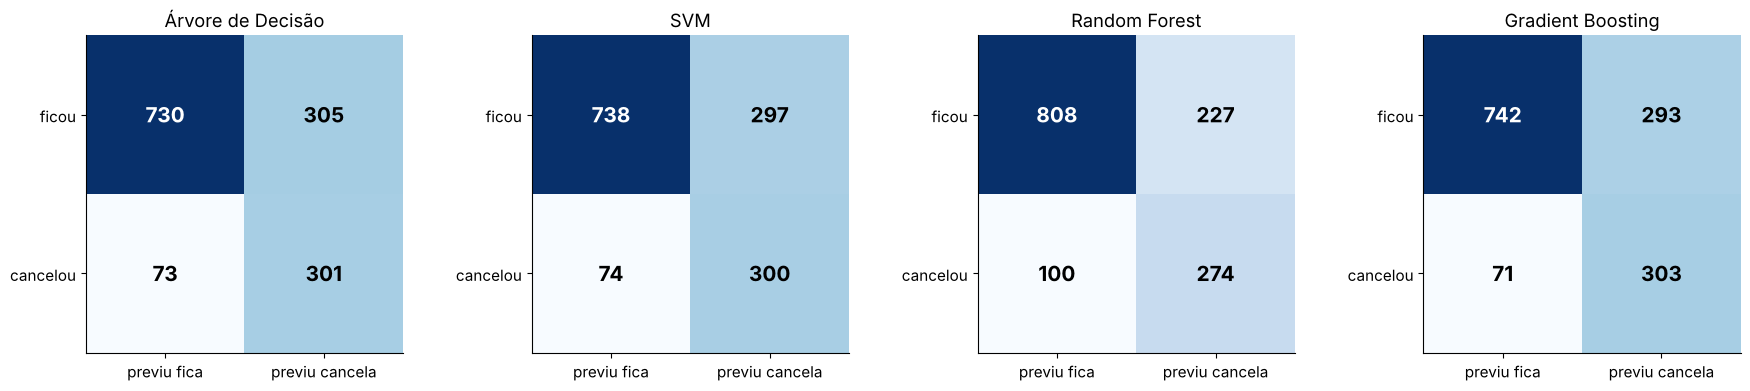

In [24]:
# Matriz de confusão: linhas = real, colunas = previsto
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, nome in zip(axes, modelos):
    m = confusion_matrix(y_teste, previsoes[nome])
    ax.imshow(m, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, m[i, j], ha='center', va='center', fontsize=15, fontweight='bold',
                    color='white' if m[i, j] > m.max() / 2 else 'black')
    ax.set_xticks([0, 1], ['previu fica', 'previu cancela'])
    ax.set_yticks([0, 1], ['ficou', 'cancelou'])
    ax.set_title(nome)
plt.tight_layout()
plt.show()

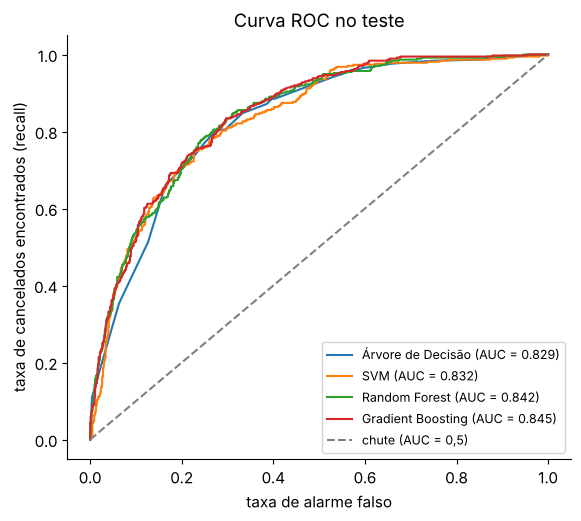

In [25]:
# Curva ROC
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for nome in modelos:
    fpr, tpr, _ = roc_curve(y_teste, notas[nome])
    ax.plot(fpr, tpr, label=f"{nome} (AUC = {tabela.loc[nome, 'ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], '--', color='gray', label='chute (AUC = 0,5)')
ax.set_xlabel('taxa de alarme falso')
ax.set_ylabel('taxa de cancelados encontrados (recall)')
ax.set_title('Curva ROC no teste')
ax.legend(fontsize=9)
plt.show()

In [26]:
# Modelo final: maior ROC-AUC entre os que dão probabilidade
com_probabilidade = [n for n in modelos if hasattr(modelos[n], 'predict_proba')]
melhor_nome = tabela.loc[com_probabilidade, 'ROC-AUC'].idxmax()
melhor = modelos[melhor_nome]

print('Modelo escolhido:', melhor_nome)
print(tabela.loc[melhor_nome])

Modelo escolhido: Gradient Boosting
Accuracy     0.742
Precision    0.508
Recall       0.810
F1           0.625
ROC-AUC      0.845
Name: Gradient Boosting, dtype: float64


**Leitura:**
- Os 4 modelos ficaram **muito parecidos**: F1 entre 0,614 e 0,626 e ROC-AUC entre 0,829 e 0,845. É o mesmo que Verbeke et al. (2012) acharam em 11 operadoras: vários modelos chegam em resultados próximos, e o que mais pesa são os dados.
- O **Gradient Boosting** teve o **maior ROC-AUC (0,845)** e o **maior recall (0,810)**: dos 374 clientes que cancelaram no teste, ele encontrou **303** e deixou escapar 71.
- O **Random Forest** teve a maior acurácia (0,768) e precision (0,547), mas deixou escapar **100** clientes.
- A precision de ~0,51 quer dizer que, de cada 2 clientes que o modelo aponta, 1 cancela de verdade. Pra retenção isso é aceitável: procurar um cliente que não ia sair custa pouco, e perder um que ia sair custa a mensalidade de vários meses.

**Modelo escolhido: Gradient Boosting.**

### 9.5 Olhando dentro da Árvore de Decisão

Mostrando só as **2 primeiras perguntas** da árvore, pra ver a lógica que ela aprendeu. Cada caixa mostra a pergunta, a proporção de clientes que chegou ali e a classe que ela "vota" (já considerando o peso maior pra quem cancela).

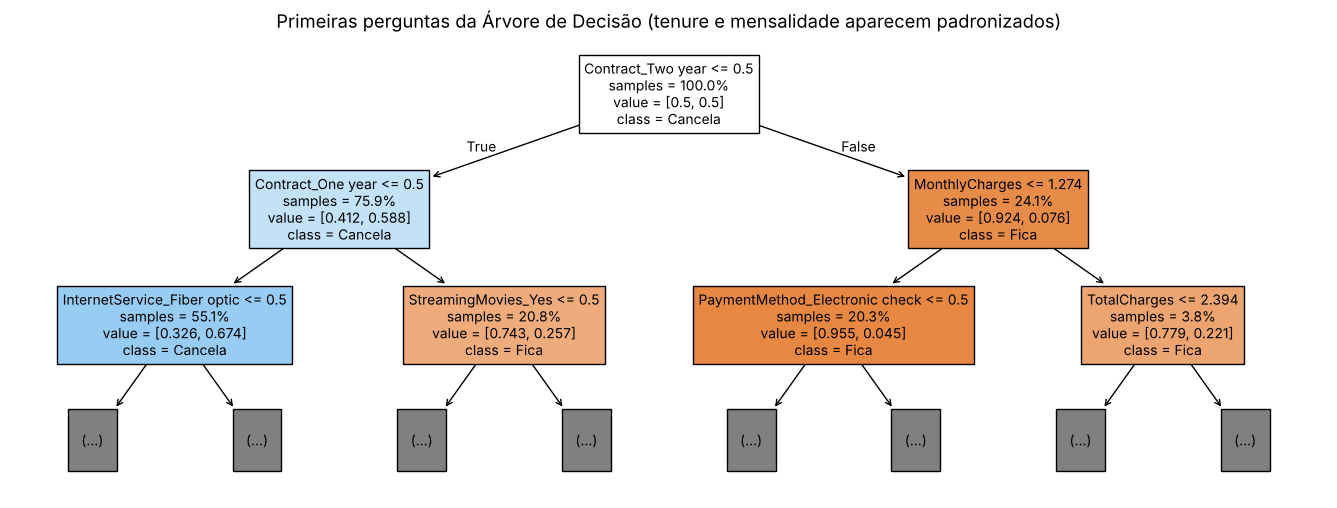

In [27]:
arvore = modelos['Árvore de Decisão']
# Nomes das colunas sem o prefixo num__ / cat__
nomes_colunas = [n.split('__', 1)[1] for n in arvore.named_steps['prep'].get_feature_names_out()]

plt.figure(figsize=(17, 6))
plot_tree(arvore.named_steps['modelo'], max_depth=2, feature_names=nomes_colunas,
          class_names=['Fica', 'Cancela'], filled=True, impurity=False, proportion=True, fontsize=10)
plt.title('Primeiras perguntas da Árvore de Decisão (tenure e mensalidade aparecem padronizados)')
plt.show()

**Como ler:** `Contract_Two year <= 0.5` quer dizer "o contrato **não** é de 2 anos?" (a coluna vale 0 ou 1). Se sim, vai pra esquerda (True).
- **Primeira pergunta:** é contrato de 2 anos? Se for (direita), quase todo mundo fica.
- **Segunda pergunta (esquerda):** também não é de 1 ano? Então é **mensal**.
- **Terceira pergunta:** tem **fibra**? Entre os clientes de contrato mensal, quem tem fibra vai pra um nó com **77%** do peso em "Cancela"; sem fibra, fica em 51%. Depois disso (não aparece no desenho) a árvore pergunta o **tempo de casa**.

A árvore chegou sozinha na mesma lógica que a EDA mostrou: **contrato** primeiro, depois **tipo de internet**.

### 9.6 O que mais pesa na decisão do modelo escolhido

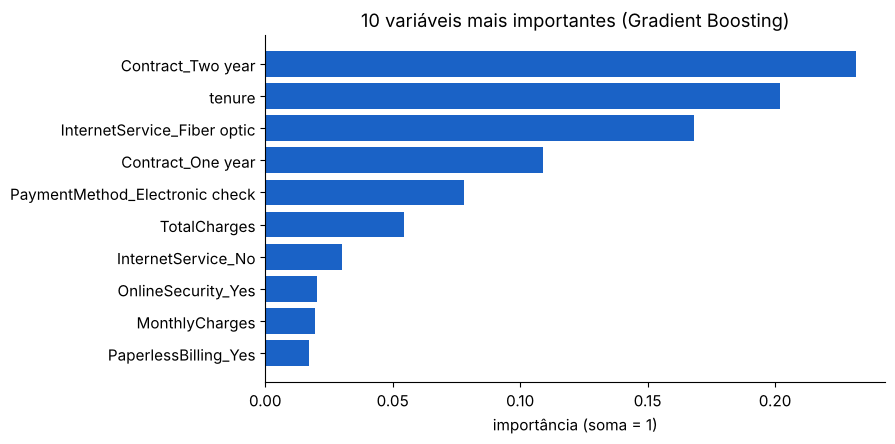

Contract_Two year                 23.2%
tenure                            20.2%
InternetService_Fiber optic       16.8%
Contract_One year                 10.9%
PaymentMethod_Electronic check     7.8%
TotalCharges                       5.4%
InternetService_No                 3.0%
OnlineSecurity_Yes                 2.0%
MonthlyCharges                     2.0%
PaperlessBilling_Yes               1.7%
dtype: str

In [28]:
nomes_colunas = [n.split('__', 1)[1] for n in melhor.named_steps['prep'].get_feature_names_out()]
importancia = pd.Series(melhor.named_steps['modelo'].feature_importances_, index=nomes_colunas)
top10 = importancia.sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top10.index[::-1], top10.values[::-1], color=AZUL)
ax.set_title(f'10 variáveis mais importantes ({melhor_nome})')
ax.set_xlabel('importância (soma = 1)')
plt.show()

(top10 * 100).round(1).astype(str) + '%'

**Leitura:** o que mais pesa é o **tipo de contrato** (2 anos + 1 ano somam 34,1%), depois o **tempo de casa** (20,2%), a **fibra** (16,8%) e o **electronic check** (7,8%). São as mesmas variáveis que apareceram na EDA e no K-means, o que dá confiança no resultado.

Cuidado: a importância mostra **o quanto** o modelo usa a variável, não **pra que lado** ela empurra. O lado vem da EDA: contrato longo e mais tempo de casa **diminuem** o risco; fibra e electronic check **aumentam**.

## 10. Juntando as duas partes: receita em risco

Saber **quem** vai sair não basta. A equipe de retenção tem tempo e desconto limitados, então precisa saber **por onde começar**. Pra isso juntamos as duas partes:

**receita em risco = chance de cancelar × mensalidade**

Exemplo: um cliente que paga 100 por mês e tem 80% de chance de sair tem **80 de receita em risco por mês**. Um que paga 30 com 90% de chance tem 27. Os dois são de risco alto, mas o primeiro deve ser procurado antes.

Fazemos isso só nos **clientes de teste**, que o modelo nunca viu, pra simular o uso real.

In [29]:
resultado = X_teste[['tenure', 'MonthlyCharges', 'Contract', 'InternetService', 'PaymentMethod']].copy()
resultado.insert(0, 'customerID', df.loc[X_teste.index, 'customerID'])
resultado['grupo'] = df.loc[X_teste.index, 'grupo']                # parte 1 (K-means)
resultado['prob_cancelar'] = melhor.predict_proba(X_teste)[:, 1]   # parte 2 (modelo)
resultado['receita_em_risco'] = resultado['prob_cancelar'] * resultado['MonthlyCharges']
resultado['cancelou_de_verdade'] = y_teste

# Fila de retenção: maior risco em dinheiro primeiro
resultado = resultado.sort_values('receita_em_risco', ascending=False)

receita_total = resultado['MonthlyCharges'].sum()
receita_perdida = resultado.loc[resultado['cancelou_de_verdade'] == 1, 'MonthlyCharges'].sum()
print(f'Clientes no teste: {len(resultado)}')
print(f'Receita mensal desses clientes: {receita_total:,.0f}')
print(f'Receita que realmente foi perdida (quem cancelou): {receita_perdida:,.0f} ({receita_perdida / receita_total:.1%})')

Clientes no teste: 1409
Receita mensal desses clientes: 90,301
Receita que realmente foi perdida (quem cancelou): 27,215 (30.1%)


**O modelo ajuda a priorizar?** Se a empresa só tiver fôlego pra procurar uma parte dos clientes, quanto do problema ela pega começando pelo topo da fila?

In [30]:
taxa_base = resultado['cancelou_de_verdade'].mean()
linhas = []
for pct in [0.10, 0.20, 0.30]:
    topo = resultado.head(int(len(resultado) * pct))   # topo da fila
    linhas.append({
        'procurando os primeiros': f'{pct:.0%} da fila',
        'clientes': len(topo),
        '% que cancelou de verdade': f"{topo['cancelou_de_verdade'].mean():.1%}",
        'quantas vezes a média (lift)': round(topo['cancelou_de_verdade'].mean() / taxa_base, 2),
        '% dos cancelados encontrados': f"{topo['cancelou_de_verdade'].sum() / resultado['cancelou_de_verdade'].sum():.1%}",
        '% da receita perdida encontrada': f"{topo.loc[topo['cancelou_de_verdade'] == 1, 'MonthlyCharges'].sum() / receita_perdida:.1%}",
    })
print(f'Taxa de cancelamento no teste (escolhendo cliente ao acaso): {taxa_base:.1%}')
pd.DataFrame(linhas).set_index('procurando os primeiros')

Taxa de cancelamento no teste (escolhendo cliente ao acaso): 26.5%


,clientes,% que cancelou de verdade,quantas vezes a média (lift),% dos cancelados encontrados,% da receita perdida encontrada
procurando os primeiros,,,,,
10% da fila,140,60.7%,2.29,22.7%,29.2%
20% da fila,281,61.6%,2.32,46.3%,55.5%
30% da fila,422,53.6%,2.02,60.4%,71.5%


**Leitura:** procurando só os **20% primeiros da fila** (281 clientes), a empresa encontra **46,3% de todos que iam cancelar** e **55,5% da receita que seria perdida**. Nessa faixa, **61,6%** cancelam de verdade, **2,3 vezes** a média. Escolhendo 20% dos clientes ao acaso, ela encontraria só uns 20% dos cancelados.

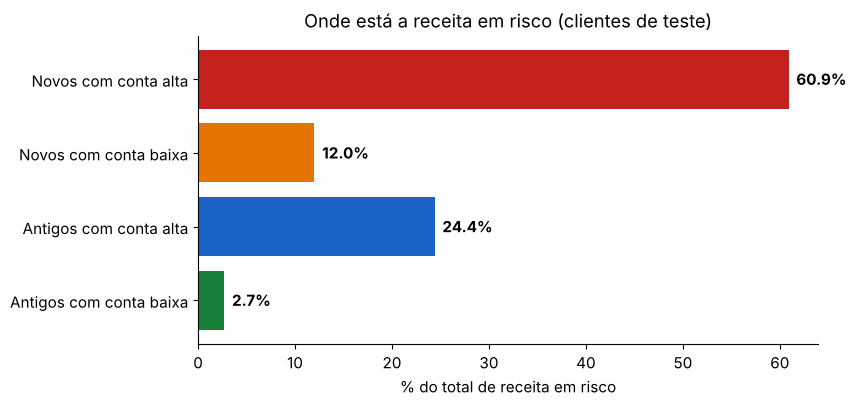

,clientes,pct_cancelou_de_verdade,chance_media_prevista,receita_em_risco,pct_da_receita_em_risco
grupo,,,,,
Novos com conta alta,463,48.8,67.4,25708.3,60.9
Novos com conta baixa,341,26.4,40.3,5042.4,12.0
Antigos com conta alta,366,13.1,29.2,10301.3,24.4
Antigos com conta baixa,239,4.2,11.6,1140.8,2.7


In [31]:
# Receita em risco por grupo
por_grupo = resultado.groupby('grupo').agg(
    clientes=('customerID', 'size'),
    pct_cancelou_de_verdade=('cancelou_de_verdade', lambda s: s.mean() * 100),
    chance_media_prevista=('prob_cancelar', lambda s: s.mean() * 100),
    receita_em_risco=('receita_em_risco', 'sum'),
).reindex(ordem_grupos)
por_grupo['pct_da_receita_em_risco'] = por_grupo['receita_em_risco'] / por_grupo['receita_em_risco'].sum() * 100
por_grupo = por_grupo.round(1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(por_grupo.index[::-1], por_grupo['pct_da_receita_em_risco'][::-1], color=[CORES[g] for g in ordem_grupos][::-1])
for i, v in enumerate(por_grupo['pct_da_receita_em_risco'][::-1]):
    ax.text(v + 0.8, i, f'{v:.1f}%', va='center', fontweight='bold')
ax.set_title('Onde está a receita em risco (clientes de teste)')
ax.set_xlabel('% do total de receita em risco')
plt.show()
por_grupo

**Leitura:**
- **60,9%** da receita em risco está no grupo **Novos com conta alta**, que é só 33% dos clientes de teste. É ali que a equipe deve começar.
- **Antigos com conta alta** cancelam pouco (13,1%), mas como pagam caro ficam com **24,4%** da receita em risco. Perder um deles dói mais que perder vários do plano básico.
- **Antigos com conta baixa** quase não cancelam (4,2%) e têm só 2,7% da receita em risco. Dar desconto pra eles seria jogar dinheiro fora.

**Cuidado com o valor exato:** a chance média prevista (por exemplo 67,4% nos "Novos com conta alta") fica **acima** do que aconteceu de verdade (48,8%). Isso acontece porque, no treino, demos peso maior pra quem cancela. Por isso a receita em risco serve muito bem pra **ordenar** clientes e **comparar** grupos, mas o total em dinheiro sai maior que o real.

### 10.1 A saída pra área de negócio: lista de retenção

Isso é o que a equipe receberia: os clientes em ordem de prioridade, com o grupo, a chance de sair, quanto está em risco e a ação sugerida pro grupo dele.

In [32]:
acoes = {
    'Novos com conta alta':  'Oferecer contrato de 1 ano com desconto e checar a qualidade da fibra',
    'Novos com conta baixa': 'Acompanhar os primeiros meses e oferecer débito automático com bônus',
    'Antigos com conta alta': 'Atendimento prioritário e benefício de fidelidade (cliente valioso)',
    'Antigos com conta baixa': 'Não precisa de desconto; oferecer upgrade de plano',
}
resultado['acao_sugerida'] = resultado['grupo'].map(acoes)

lista = resultado.head(10)[['customerID', 'grupo', 'Contract', 'tenure', 'MonthlyCharges',
                            'prob_cancelar', 'receita_em_risco', 'acao_sugerida', 'cancelou_de_verdade']].copy()
lista['prob_cancelar'] = (lista['prob_cancelar'] * 100).round(1).astype(str) + '%'
lista['receita_em_risco'] = lista['receita_em_risco'].round(2)
print(f"Dos 10 primeiros da fila, {int(lista['cancelou_de_verdade'].sum())} cancelaram de verdade.")
lista.reset_index(drop=True).rename(index=lambda i: i + 1)

Dos 10 primeiros da fila, 9 cancelaram de verdade.


,customerID,grupo,Contract,tenure,MonthlyCharges,prob_cancelar,receita_em_risco,acao_sugerida,cancelou_de_verdade
1,3292-PBZEJ,Novos com conta alta,Month-to-month,11,111.40,87.9%,97.89,Oferecer contrato de 1 ano com desconto e chec...,0
2,4587-VVTOX,Novos com conta alta,Month-to-month,6,105.30,90.7%,95.52,Oferecer contrato de 1 ano com desconto e chec...,1
3,8884-ADFVN,Novos com conta alta,Month-to-month,7,101.95,92.1%,93.86,Oferecer contrato de 1 ano com desconto e chec...,1
4,7181-BQYBV,Novos com conta alta,Month-to-month,1,102.45,91.5%,93.70,Oferecer contrato de 1 ano com desconto e chec...,1
5,2027-FECZV,Novos com conta alta,Month-to-month,12,106.70,87.0%,92.78,Oferecer contrato de 1 ano com desconto e chec...,1
6,6023-YEBUP,Novos com conta alta,Month-to-month,3,100.95,91.6%,92.49,Oferecer contrato de 1 ano com desconto e chec...,1
7,9221-OTIVJ,Novos com conta alta,Month-to-month,14,104.85,88.0%,92.24,Oferecer contrato de 1 ano com desconto e chec...,1
8,6861-XWTWQ,Novos com conta alta,Month-to-month,7,99.25,92.1%,91.38,Oferecer contrato de 1 ano com desconto e chec...,1
9,1400-MMYXY,Novos com conta alta,Month-to-month,3,105.90,86.0%,91.05,Oferecer contrato de 1 ano com desconto e chec...,1
10,9851-KIELU,Novos com conta alta,Month-to-month,10,110.10,81.9%,90.13,Oferecer contrato de 1 ano com desconto e chec...,1


In [33]:
# Exemplo: o 2º da fila (o 1º está no texto abaixo)
c = resultado.iloc[1]
print('=' * 62)
print(f"  CLIENTE {c['customerID']}  |  2º da fila de retenção")
print('=' * 62)
print(f"  Grupo (K-means):        {c['grupo']}")
print(f"  Contrato:               {c['Contract']}")
print(f"  Tempo de casa:          {c['tenure']} meses")
print(f"  Internet:               {c['InternetService']}")
print(f"  Pagamento:              {c['PaymentMethod']}")
print(f"  Mensalidade:            {c['MonthlyCharges']:.2f}")
print('-' * 62)
print(f"  Chance de cancelar:     {c['prob_cancelar']:.1%}")
print(f"  Receita em risco/mês:   {c['receita_em_risco']:.2f}")
print(f"  Ação sugerida:          {c['acao_sugerida']}")
print('-' * 62)
print(f"  O que aconteceu de verdade: {'CANCELOU' if c['cancelou_de_verdade'] == 1 else 'ficou'}")
print('=' * 62)

  CLIENTE 4587-VVTOX  |  2º da fila de retenção
  Grupo (K-means):        Novos com conta alta
  Contrato:               Month-to-month
  Tempo de casa:          6 meses
  Internet:               Fiber optic
  Pagamento:              Electronic check
  Mensalidade:            105.30
--------------------------------------------------------------
  Chance de cancelar:     90.7%
  Receita em risco/mês:   95.52
  Ação sugerida:          Oferecer contrato de 1 ano com desconto e checar a qualidade da fibra
--------------------------------------------------------------
  O que aconteceu de verdade: CANCELOU


**Por que o 2º e não o 1º?** O 1º da fila tinha 87,9% de chance e acabou **ficando**: o modelo erra, e isso é esperado com uma precision de ~0,51. Mas dos **10 primeiros da fila, 9 cancelaram de verdade**. Na prática, a equipe que liga pra esses 10 pega 9 clientes que iam embora.

## 11. Conclusão

**Respondendo a pergunta do projeto:**

1. **Que tipos de cliente existem?** O K-means separou a base em **4 grupos** usando só tempo de casa e mensalidade. O grupo de maior risco é o dos **Novos com conta alta**: 31% da base, quase todos com fibra e contrato mensal, e **49,2% deles cancelaram**, quase o dobro da média (26,5%).
2. **Quem vai sair?** O melhor modelo foi o **Gradient Boosting**, com **ROC-AUC de 0,845** e **recall de 0,810**: ele encontra **8 de cada 10 clientes** que cancelam. Os outros modelos ficaram perto, o que bate com a pesquisa de Verbeke et al. (2012).
3. **Quanto está em jogo e por onde começar?** Ordenando os clientes pela receita em risco, os **20% primeiros da fila** concentram **55,5% da receita que seria perdida**. Dos 10 primeiros, 9 cancelaram de verdade.

**O modelo ajuda a decidir melhor?** Sim. Sem modelo, procurar 20% dos clientes ao acaso pegaria uns 20% dos cancelamentos. Com o modelo, a mesma equipe, com o mesmo esforço, encontra **46,3%** dos clientes que iam sair.

**Principais variáveis:** tipo de contrato, tempo de casa, internet de fibra e pagamento por electronic check.

**Recomendação prática por grupo:**

| Grupo | Situação | Ação |
|---|---|---|
| Novos com conta alta | maior risco e 60,9% da receita em risco | oferecer contrato de 1 ano com desconto e verificar a qualidade da fibra |
| Antigos com conta alta | cancelam pouco, mas são os mais valiosos | atendimento prioritário e benefício de fidelidade |
| Novos com conta baixa | risco médio, conta baixa | acompanhar os primeiros meses e incentivar o débito automático |
| Antigos com conta baixa | quase não cancelam | não gastar desconto; oferecer upgrade de plano |

E duas ações que valem pra todo mundo:
- **Levar o cliente do contrato mensal pro anual.** No mensal, 42,7% cancelam; no de 1 ano, 11,3%; no de 2 anos, 2,8%.
- **Incentivar o pagamento automático.** No electronic check, 45,3% cancelam; no débito automático ou cartão, uns 15% a 17%.

**Limitações e cuidados:**
- **A base é fictícia** (IBM, operadora dos EUA). Os padrões fazem sentido, mas os números não valem direto pra uma operadora brasileira. O modelo teria que ser treinado de novo com dados reais.
- **É uma foto de um momento só.** Não tem histórico mês a mês, como ligações pro SAC, reclamações, uso de dados e atrasos, que costumam ajudar muito a prever churn.
- **Não sabemos o motivo do cancelamento** (preço, concorrente, mudança de cidade).
- **As probabilidades ficam infladas** por causa do peso maior pra quem cancela. Servem pra ordenar, mas pra um valor exato em dinheiro seria preciso calibrar o modelo.
- **Correlação não é causa.** A fibra cancelar mais não prova que a fibra é ruim; pode ser o preço. As ações sugeridas deveriam ser testadas (um grupo recebe a oferta e outro não) antes de virar regra.
- **Não colocamos o custo da ação de retenção.** Como Verbeke et al. (2012) sugerem, o próximo passo seria incluir quanto custa cada oferta e calcular até que ponto da fila vale a pena ligar.
- **O K-means usou só 2 variáveis.** Fica simples de explicar e de desenhar, mas deixa de fora contrato e serviços.

## 12. Referências

- GALLO, A. **The Value of Keeping the Right Customers.** Harvard Business Review, 29 out. 2014. Disponível em: https://hbr.org/2014/10/the-value-of-keeping-the-right-customers
- IBM. **Telco customer churn (11.1.3+).** IBM Community, 2019. Disponível em: https://community.ibm.com/community/user/businessanalytics/blogs/steven-macko/2019/07/11/telco-customer-churn-1113
- IBM. **Telco-Customer-Churn.csv.** GitHub. Disponível em: https://github.com/IBM/telco-customer-churn-on-icp4d. Acesso em: 06 nov. 2026.
- KAGGLE. **Telco Customer Churn.** Disponível em: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
- MEDEIROS, H. **Pós-pago chega a 70% da receita de serviço móvel da TIM no segundo trimestre.** Mobile Time, 27 jul. 2026. Disponível em: https://www.mobiletime.com.br/noticias/27/07/2026/tim-pos-pago-movel-70/
- PAULO, D. **Mercado móvel ganha 1,26 milhão de acessos no Brasil em setembro.** Teletime, 03 nov. 2026. Disponível em: https://teletime.com.br/03/11/2026/mercado-movel-setembro-2026/
- VERBEKE, W.; DEJAEGER, K.; MARTENS, D.; HUR, J.; BAESENS, B. **New insights into churn prediction in the telecommunication sector: a profit driven data mining approach.** European Journal of Operational Research, v. 218, n. 1, p. 211-229, 2012. DOI: 10.1016/j.ejor.2011.09.031
- PEDREGOSA, F. et al. **Scikit-learn: Machine Learning in Python.** Journal of Machine Learning Research, v. 12, p. 2825-2830, 2011.